In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import to_rgba
from matplotlib.lines import Line2D
from pathlib import Path
import torch
from cellpose import models, io
from skimage.segmentation import find_boundaries
from skimage.color import label2rgb

In [2]:
input_csv_name = "combined_segmentation_quality_v2.csv"
df = pd.read_csv(input_csv_name)
print(df.shape)
df.tail(2)

(993, 59)


,image_id,dataset,model,n_true,n_predicted,count_error,TP,FP,FN,precision,...,intensity_p99,contrast,laplacian_variance,noise_estimate,n_cells,cell_density,foreground_fraction,mean_cell_area,median_cell_area,cell_area_cv
991,flow_chamber_dataset/training_dataset/training...,flow_chamber_dataset/training_dataset/training...,cpsam_v2,46,55,9,46,9,0,0.836364,...,13299.0,3689.0,0.000152,0.002735,46,23.469388,0.017001,724.391304,671.0,0.331508
992,flow_chamber_dataset/training_dataset/training...,flow_chamber_dataset/training_dataset/training...,cpsam_v2,47,51,4,47,4,0,0.921569,...,13289.0,3674.0,0.000151,0.002744,47,23.979592,0.017867,745.106383,711.0,0.298626


                                                                                                                       image_id                                                     dataset  rank_sum
                                                                                             official_dataset/train/276_img.png                                      official_dataset/train    2310.5
breast_cancer_cell_dataset/training_dataset/training_source/cell migration R1 - Position 0_XY1562686096_Z0_T00_C1-1-image14.tif breast_cancer_cell_dataset/training_dataset/training_source    2318.0
                                                                                       official_dataset/train_cyto2/760_img.png                                official_dataset/train_cyto2    2456.5
                                                                                             official_dataset/train/221_img.png                                      official_dataset/train    3162.0
          

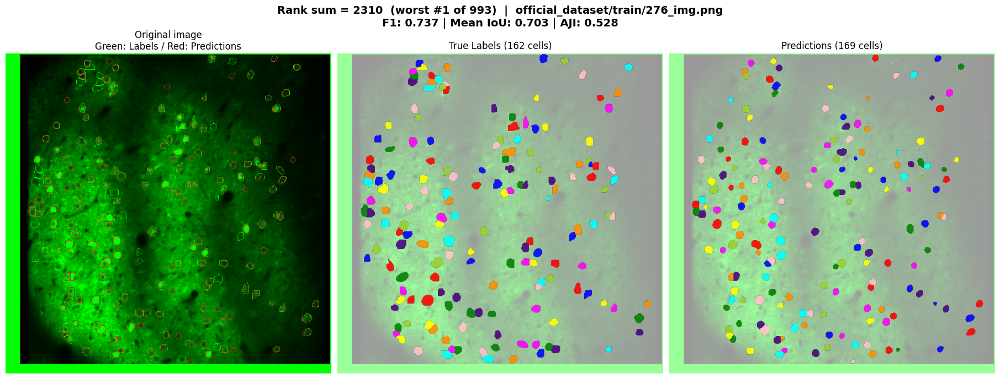

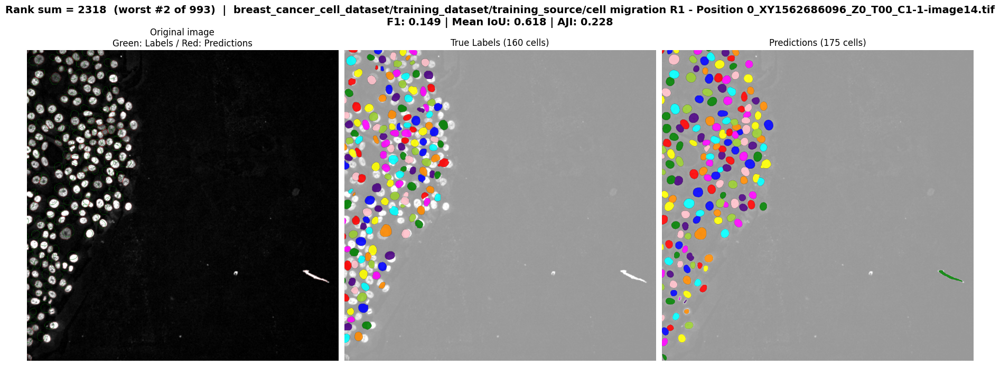

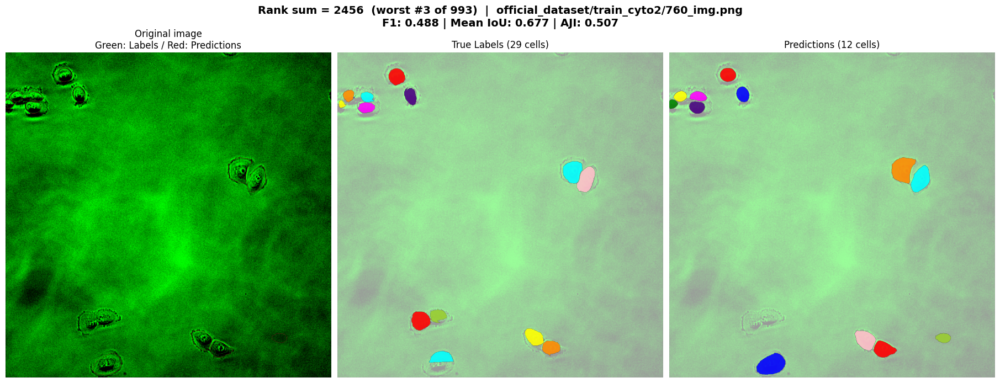

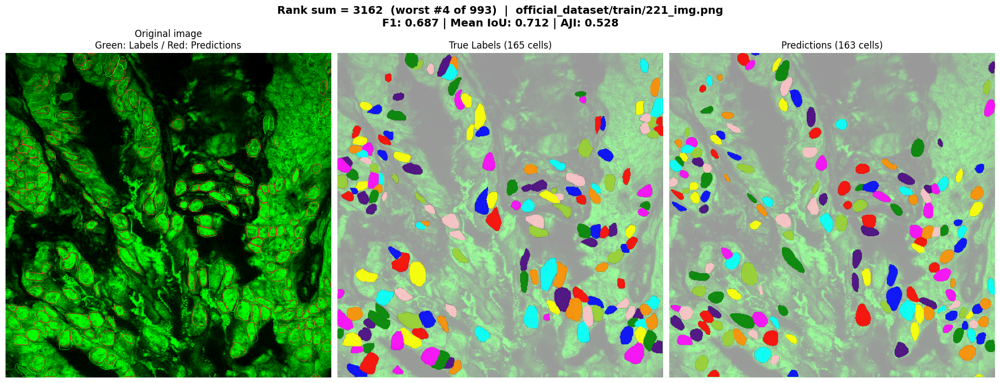

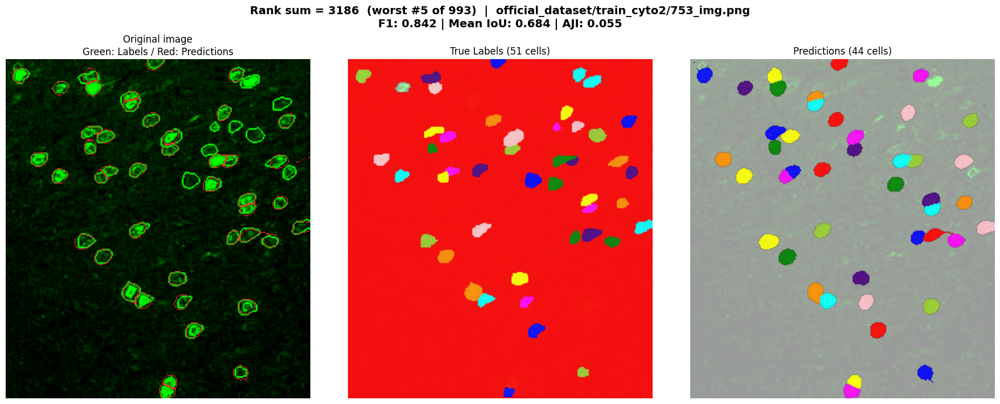

...

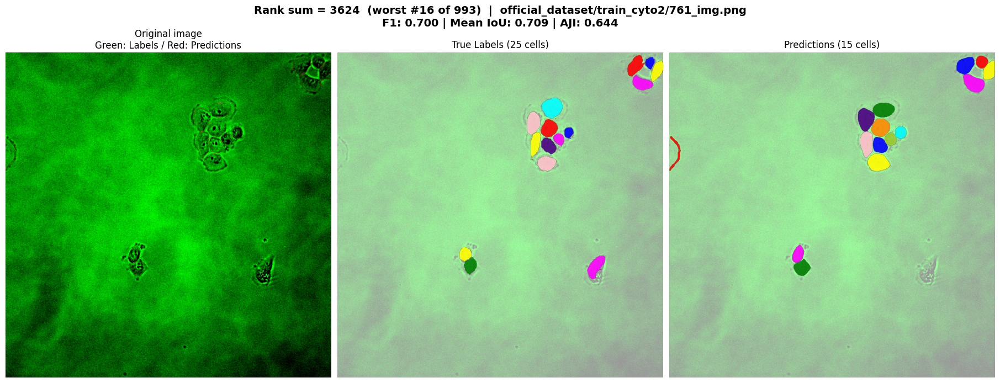

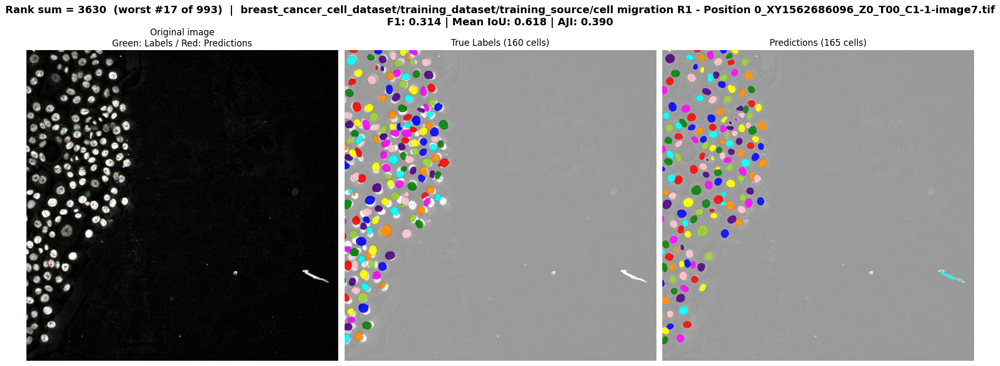

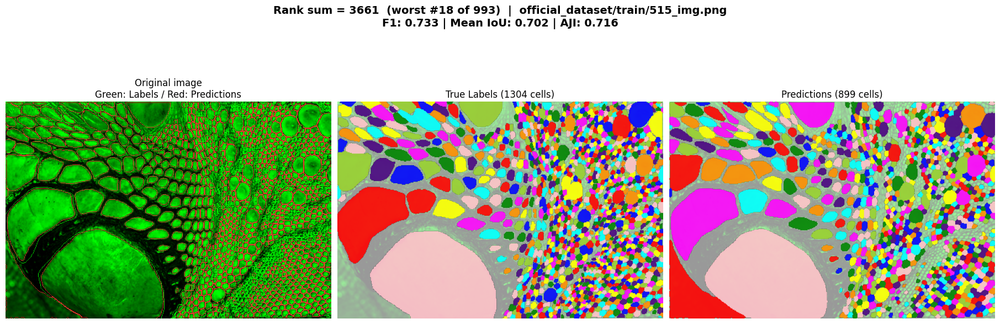

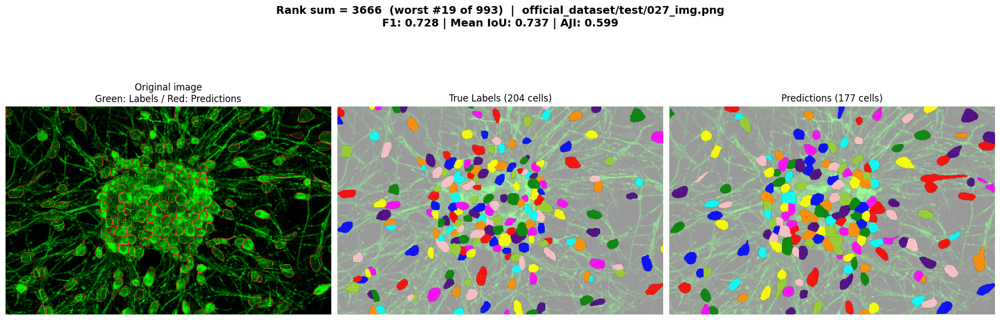

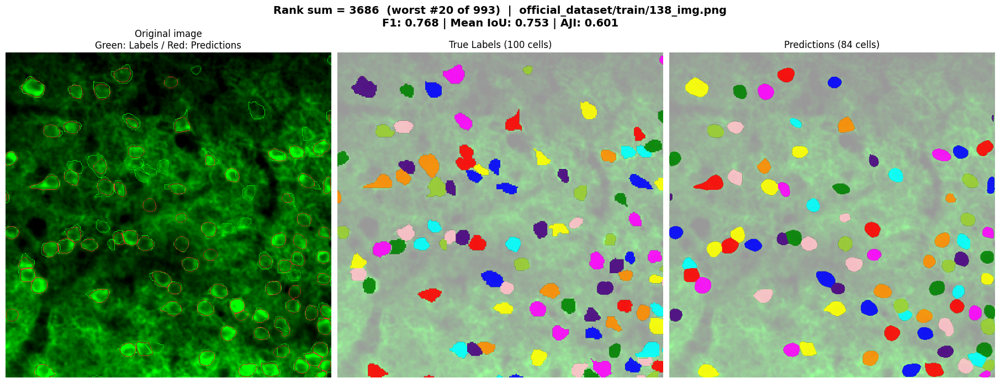

In [ ]:
N_WORST = 20

metrics_list = [
    "precision", "recall", "f1", "ap50", "ap75", "ap90", "count_error",
    "b_prec_50", "b_prec_75", "b_prec_90",
    "b_rec_50", "b_rec_75", "b_rec_90",
    "b_f1_50", "b_f1_75", "b_f1_90",
    "mean_iou", "median_iou", "mean_dice",
    "foreground_iou", "foreground_dice", "aji_custom", "aji_official",
    "n_matched_groups", "n_split_groups", "n_merged_groups",
    "n_complex_groups", "n_missed_groups", "n_artifact_groups",
]

# Metrics where a HIGHER value is worse (all others: a lower value is worse)
HIGHER_IS_WORSE = ["n_split_groups", "n_merged_groups", "n_complex_groups",
                   "n_missed_groups", "n_artifact_groups"]
# Metrics where a value FAR FROM 0 is worse (in either direction)
ABS_IS_WORSE = ["count_error"]

df = df.dropna(subset=metrics_list)

ranks = pd.DataFrame(index=df.index)
for m in metrics_list:
    values = df[m].abs() if m in ABS_IS_WORSE else df[m]
    lower_is_worse = m not in HIGHER_IS_WORSE and m not in ABS_IS_WORSE
    # ascending=True: lowest value gets rank 1;  ascending=False: highest value gets rank 1
    ranks[m] = values.rank(ascending=lower_is_worse, na_option="top")   # NaN -> worst ranks

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = models.CellposeModel(pretrained_model="cpsam_v2", device=device)

def to_display(img):
    """Scale each channel to 0-1 for display (the model still gets the raw image)."""
    img = img.astype(float)
    if img.ndim == 2:                          # grayscale -> 3 channels
        img = np.stack([img] * 3, axis=-1)
    out = np.zeros((*img.shape[:2], 3))
    for c in range(min(3, img.shape[-1])):
        lo, hi = np.percentile(img[..., c], (1, 99))
        if hi > lo:                            # empty channels stay black
            out[..., c] = np.clip((img[..., c] - lo) / (hi - lo), 0, 1)
    return out

df["rank_sum"] = ranks.sum(axis=1)

worst_df = df.sort_values("rank_sum").head(N_WORST)    # lowest sum = worst overall
print(worst_df[["image_id", "dataset", "rank_sum"]].to_string(index=False))

for rank, (_, worst) in enumerate(worst_df.iterrows(), start=1):
    image_id = worst["image_id"]

    # paths
    image_path = Path(image_id)
    if "_img" in image_path.name:                                      # official_dataset
        mask_path = image_path.parent / image_path.name.replace("img", "masks")
    else:                                                              # breast_cancer / flow_chamber
        mask_path = image_path.parent.parent / "training_target" / image_path.name

    # read and predict
    image = io.imread(image_path)
    true_cells = io.imread(mask_path)
    predicted_cells, _, _ = model.eval(image)

    rgb = to_display(image)
    fig, axes = plt.subplots(1, 3, figsize=(18, 7), sharex=True, sharey=True, constrained_layout=True)
    ax_input, ax_true, ax_pred = axes


    ax_input.imshow(rgb)
    true_edges = np.zeros((*true_cells.shape, 4))
    pred_edges = np.zeros((*predicted_cells.shape, 4))
    true_edges[find_boundaries(true_cells, mode="inner")] = [0, 1, 0, 0.9]
    pred_edges[find_boundaries(predicted_cells, mode="inner")] = [1, 0.2, 0.2, 0.9]
    ax_input.imshow(true_edges)
    ax_input.imshow(pred_edges)
    ax_input.set_title("Original image\nGreen: Labels / Red: Predictions")

    for ax, cells, title in [(ax_true, true_cells, "True Labels"), (ax_pred, predicted_cells, "Predictions")]:
        ax.imshow(rgb, alpha=0.4)
        overlay = np.dstack([label2rgb(cells, bg_label=0), (cells > 0) * 0.9])
        ax.imshow(overlay)
        ax.set_title(f"{title} ({len(np.unique(cells)) - 1} cells)")

    for ax in axes:
        ax.set_axis_off()

    fig.suptitle(f"Rank sum = {worst['rank_sum']:.0f}  (worst #{rank} of {len(df)})  |  {image_id}\n"
                 f"F1: {worst['f1']:.3f} | Mean IoU: {worst['mean_iou']:.3f} | AJI: {worst['aji_official']:.3f}",
                 fontsize=14, fontweight="bold")
    plt.show()

                                image_id                      dataset  rank_sum
      official_dataset/train/347_img.png       official_dataset/train   22874.0
official_dataset/train_cyto2/722_img.png official_dataset/train_cyto2   22908.5
official_dataset/train_cyto2/655_img.png official_dataset/train_cyto2   22924.5
official_dataset/train_cyto2/687_img.png official_dataset/train_cyto2   23018.0
      official_dataset/train/417_img.png       official_dataset/train   23185.5
official_dataset/train_cyto2/647_img.png official_dataset/train_cyto2   23360.0
      official_dataset/train/353_img.png       official_dataset/train   23382.0
official_dataset/train_cyto2/783_img.png official_dataset/train_cyto2   23400.0
official_dataset/train_cyto2/727_img.png official_dataset/train_cyto2   23437.0
official_dataset/train_cyto2/607_img.png official_dataset/train_cyto2   23595.0
official_dataset/train_cyto2/669_img.png official_dataset/train_cyto2   23604.0
official_dataset/train_cyto2/740_img.png

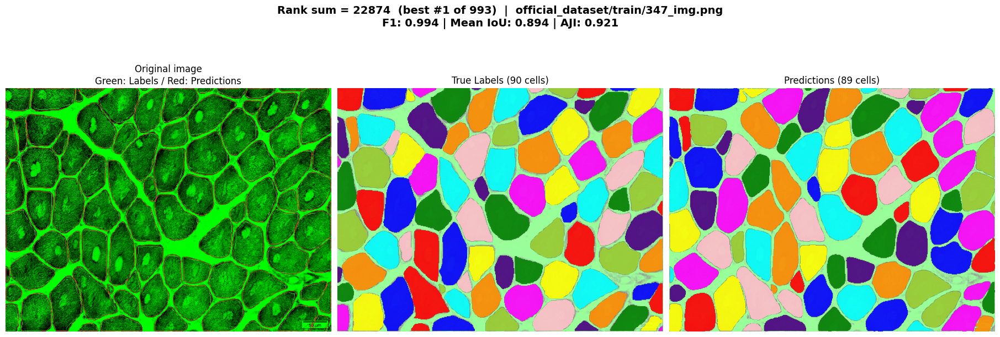

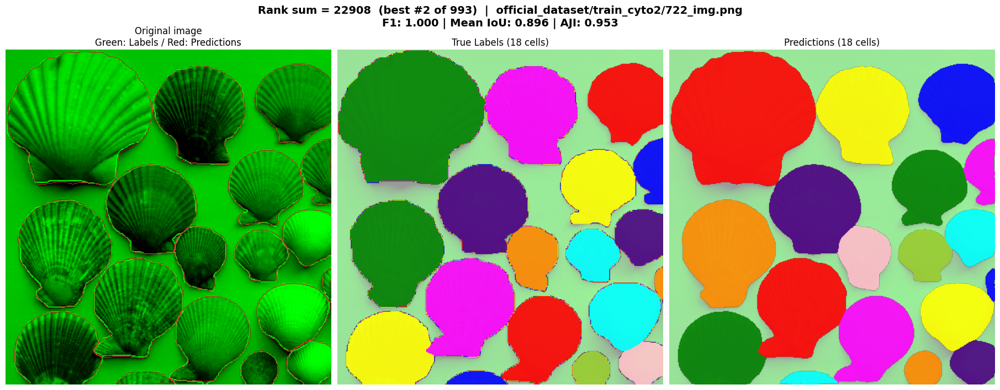

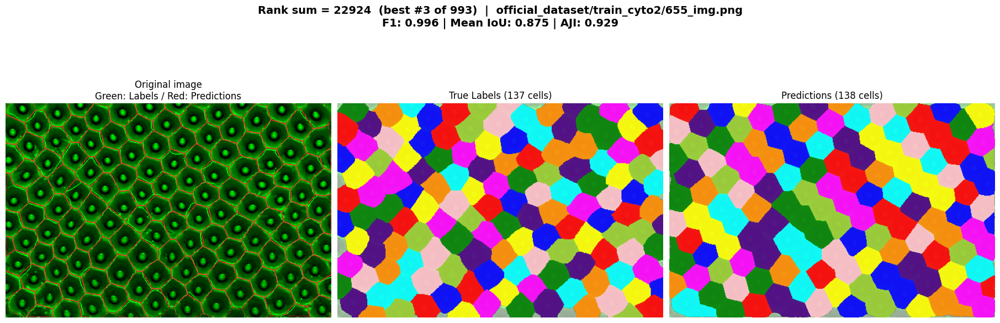

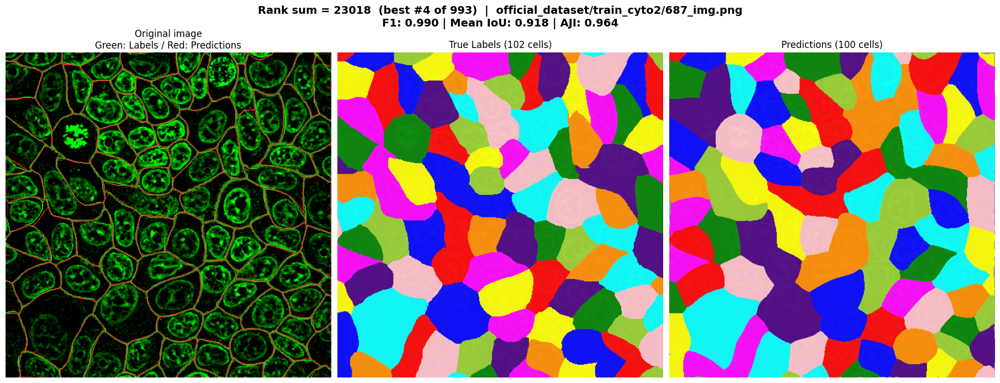

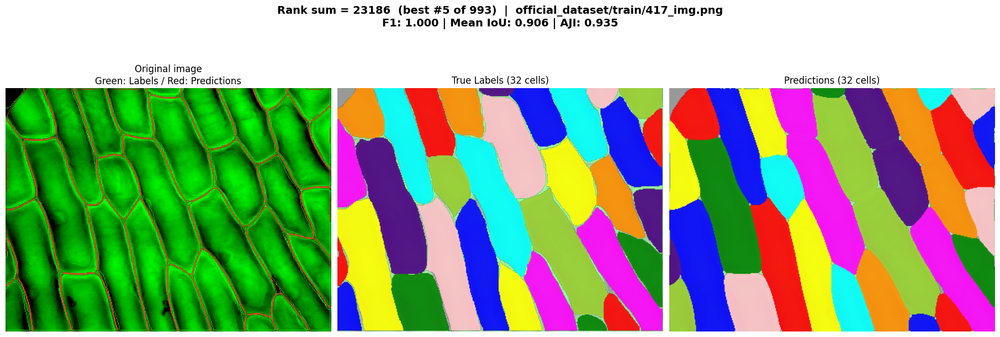

...

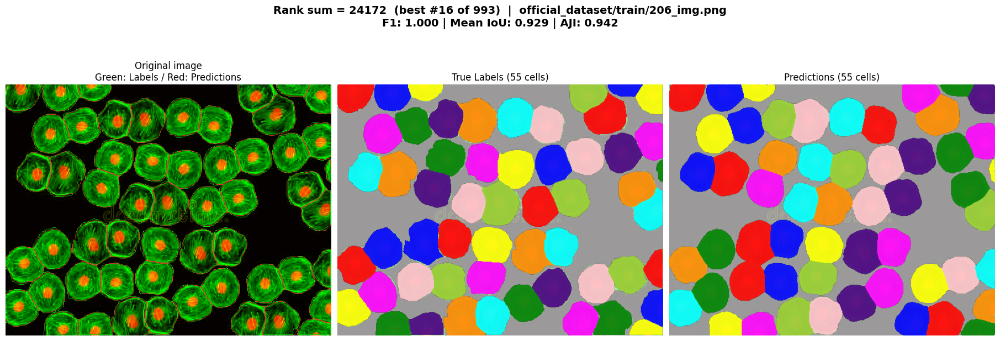

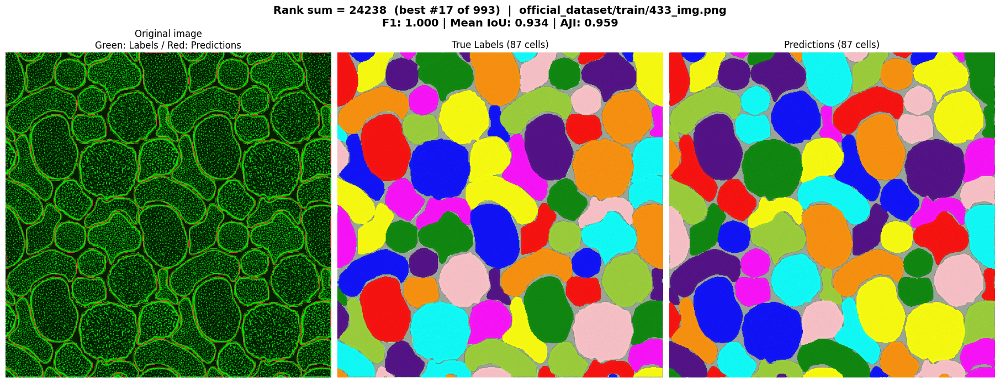

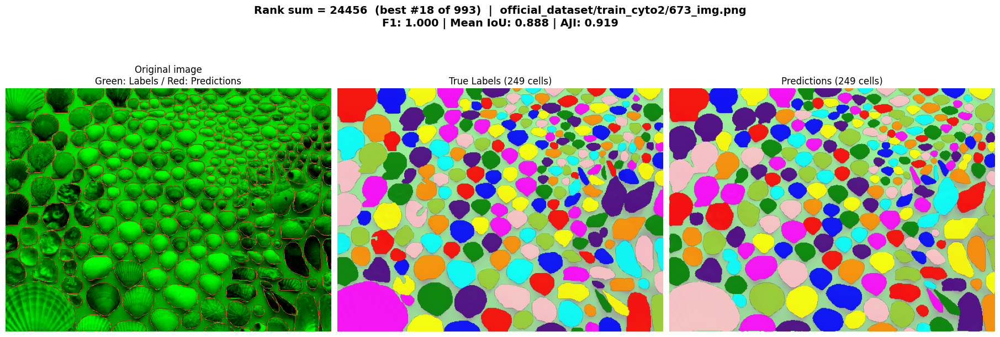

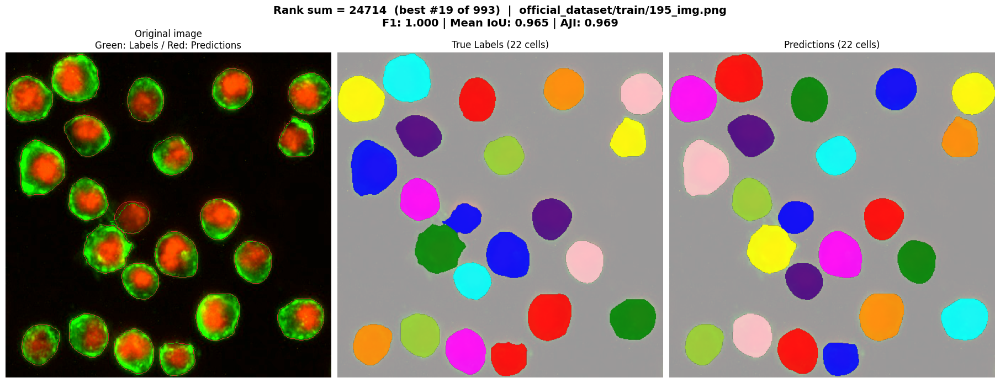

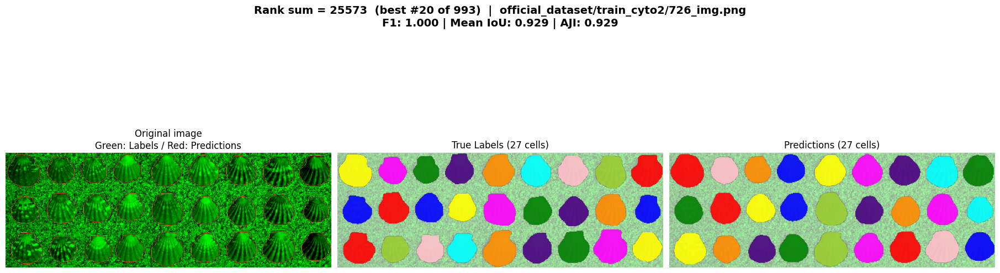

In [6]:
N_BEST = N_WORST

best_df = df.sort_values("rank_sum").tail(N_BEST) 
print(best_df[["image_id", "dataset", "rank_sum"]].to_string(index=False))

for rank, (_, best) in enumerate(best_df.iterrows(), start=1):
    image_id = best["image_id"]

    # paths
    image_path = Path(image_id)
    if "_img" in image_path.name:                                      # official_dataset
        mask_path = image_path.parent / image_path.name.replace("img", "masks")
    else:                                                              # breast_cancer / flow_chamber
        mask_path = image_path.parent.parent / "training_target" / image_path.name

    # read and predict
    image = io.imread(image_path)
    true_cells = io.imread(mask_path)
    predicted_cells, _, _ = model.eval(image)

    rgb = to_display(image)
    fig, axes = plt.subplots(1, 3, figsize=(18, 7), sharex=True, sharey=True, constrained_layout=True)
    ax_input, ax_true, ax_pred = axes

    ax_input.imshow(rgb)
    true_edges = np.zeros((*true_cells.shape, 4))
    pred_edges = np.zeros((*predicted_cells.shape, 4))
    true_edges[find_boundaries(true_cells, mode="inner")] = [0, 1, 0, 0.9]
    pred_edges[find_boundaries(predicted_cells, mode="inner")] = [1, 0.2, 0.2, 0.9]
    ax_input.imshow(true_edges)
    ax_input.imshow(pred_edges)
    ax_input.set_title("Original image\nGreen: Labels / Red: Predictions")

    for ax, cells, title in [(ax_true, true_cells, "True Labels"), (ax_pred, predicted_cells, "Predictions")]:
        ax.imshow(rgb, alpha=0.4)
        overlay = np.dstack([label2rgb(cells, bg_label=0), (cells > 0) * 0.9])
        ax.imshow(overlay)
        ax.set_title(f"{title} ({len(np.unique(cells)) - 1} cells)")

    for ax in axes:
        ax.set_axis_off()

    fig.suptitle(f"Rank sum = {best['rank_sum']:.0f}  (best #{rank} of {len(df)})  |  {image_id}\n"
                 f"F1: {best['f1']:.3f} | Mean IoU: {best['mean_iou']:.3f} | AJI: {best['aji_official']:.3f}",
                 fontsize=14, fontweight="bold")
    plt.show()

